# CWK1 – S&P 500 Share Segmentation: Risk-Return and Adapted RFM

##  Setup
Mounts Google Drive to save outputs and prints the package versions.

In [14]:
# Connect Google Drive so the saved files are kept after the session ends
from google.colab import drive
drive.mount('/content/drive')

import os
SAVE = '/content/drive/MyDrive/CWK1/'
os.makedirs(SAVE, exist_ok=True)

import datetime
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import yfinance as yf

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Package versions
print('pandas      ', pd.__version__)
print('numpy       ', np.__version__)
print('yfinance    ', yf.__version__)
print('scikit-learn', sklearn.__version__)
print('scipy       ', scipy.__version__)
print('matplotlib  ', matplotlib.__version__)
print('seaborn     ', sns.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pandas       2.2.3
numpy        2.4.6
yfinance     0.2.66
scikit-learn 1.6.1
scipy        1.16.3
matplotlib   3.10.0
seaborn      0.13.2


## 1.1 Ticker selection and data acquisition
Loads the saved 22 Nov 2026 snapshot from GitHub so results match the report. Set USE_SNAPSHOT = False to download fresh data from Wikipedia and Yahoo Finance.

In [15]:
START = '2021-01-01'
END = '2025-01-01'        # yfinance does not include the end date

# True  = load my saved data from GitHub (same data as the report)
# False = download everything again from Wikipedia and Yahoo Finance
USE_SNAPSHOT = True
REPO = 'https://raw.githubusercontent.com/Sanu1aRan/sp500_rfm_segmentation/refs/heads/main/'

if USE_SNAPSHOT:
    sp500 = pd.read_csv(REPO + 'sp500_constituents.csv')
    adj_close = pd.read_csv(REPO + 'adj_close.csv', index_col=0, parse_dates=True)
    close = pd.read_csv(REPO + 'close.csv', index_col=0, parse_dates=True)
    volume = pd.read_csv(REPO + 'volume.csv', index_col=0, parse_dates=True)
    gspc = pd.read_csv(REPO + 'gspc.csv', index_col=0, parse_dates=True)

    log = pd.read_csv(REPO + 'download_log.csv')
    RETRIEVED = log['retrieved_date'][0]
    if log['failed'][0] == 'none':
        failed = []
    else:
        failed = log['failed'][0].split(', ')

else:
    RETRIEVED = str(datetime.date.today())

    # S&P 500 list from Wikipedia
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    sp500 = pd.read_html(url, storage_options={'User-Agent': 'Mozilla/5.0'})[0]
    sp500['Ticker'] = sp500['Symbol'].str.replace('.', '-')     # Yahoo uses BRK-B, not BRK.B
    sp500.to_csv(SAVE + 'sp500_constituents.csv', index=False)
    all_tickers = sp500['Ticker'].tolist()

    # Download in batches of 50 so Yahoo does not block the requests
    adj_parts, close_parts, vol_parts = [], [], []
    for i in range(0, len(all_tickers), 50):
        batch = all_tickers[i:i + 50]
        data = yf.download(batch, start=START, end=END, auto_adjust=False, progress=False)
        adj_parts.append(data['Adj Close'])
        close_parts.append(data['Close'])
        vol_parts.append(data['Volume'])
        time.sleep(1)
    adj_close = pd.concat(adj_parts, axis=1)
    close = pd.concat(close_parts, axis=1)
    volume = pd.concat(vol_parts, axis=1)

    # Tickers that came back empty are retried up to two more times
    for attempt in range(2):
        failed = []
        for t in all_tickers:
            if t not in adj_close.columns or adj_close[t].isna().all():
                failed.append(t)
        if len(failed) == 0:
            break
        print('Retrying:', failed)
        time.sleep(5)
        data = yf.download(failed, start=START, end=END, auto_adjust=False, progress=False)
        for t in failed:
            if t in data['Adj Close'].columns:
                adj_close[t] = data['Adj Close'][t]
                close[t] = data['Close'][t]
                volume[t] = data['Volume'][t]

    # Check once more after the retries
    failed = []
    for t in all_tickers:
        if t not in adj_close.columns or adj_close[t].isna().all():
            failed.append(t)

    # Remove tickers with no data at all
    adj_close = adj_close.drop(columns=failed, errors='ignore')
    close = close.drop(columns=failed, errors='ignore')
    volume = volume.drop(columns=failed, errors='ignore')

    # Benchmark
    gspc = yf.download('^GSPC', start=START, end=END, auto_adjust=False, progress=False)['Adj Close']

    # Save the snapshot so the analysis can be repeated later
    adj_close.to_csv(SAVE + 'adj_close.csv')
    close.to_csv(SAVE + 'close.csv')
    volume.to_csv(SAVE + 'volume.csv')
    gspc.to_csv(SAVE + 'gspc.csv')

    if len(failed) == 0:
        failed_text = 'none'
    else:
        failed_text = ', '.join(failed)
    log = pd.DataFrame({'retrieved_date': [RETRIEVED], 'start': [START], 'end': [END],
                        'tickers_listed': [len(all_tickers)],
                        'tickers_downloaded': [adj_close.shape[1]],
                        'failed': [failed_text]})
    log.to_csv(SAVE + 'download_log.csv', index=False)

tickers = sp500['Ticker'].tolist()
print('Tickers listed:', len(tickers), '| retrieved', RETRIEVED)
print('Downloaded (days x tickers):', adj_close.shape)
print('Failed downloads:', failed)

Tickers listed: 503 | retrieved 2026-11-22
Downloaded (days x tickers): (1005, 498)
Failed downloads: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


## 1.2 Data validation and alignment
Checks dates, missing values, non-positive prices, zero volume and late listings. Shares that fail are logged in the exclusion log. No missing prices are filled.

In [16]:
dates = adj_close.index
print('Trading days:', len(dates), 'from', dates[0].date(), 'to', dates[-1].date())
print('Duplicate dates:', dates.duplicated().sum())
print('Missing benchmark values:', gspc.isna().sum().sum())

# One row per share with the result of each check
checks = pd.DataFrame(index=adj_close.columns)
checks['missing_adj'] = adj_close.isna().sum()
checks['missing_close'] = close.isna().sum()
checks['missing_vol'] = volume.isna().sum()
checks['nonpos_price'] = ((adj_close <= 0) | (close <= 0)).sum()
checks['zero_vol'] = (volume <= 0).sum()
checks['first_date'] = adj_close.apply(pd.Series.first_valid_index)
checks['last_date'] = adj_close.apply(pd.Series.last_valid_index)

# Corporate actions: very large one-day moves, and jumps in the Adj Close / Close ratio
daily_ret = adj_close.pct_change(fill_method=None)
ratio = adj_close / close
checks['extreme_moves'] = (daily_ret.abs() > 0.40).sum()
checks['ratio_jumps'] = (ratio.pct_change(fill_method=None).abs() > 0.05).sum()

# A share is kept only if it has complete, valid data for the whole period (nothing is filled)
reasons = []
for t in checks.index:
    row = checks.loc[t]
    if row['first_date'] > dates[0]:
        reasons.append('Incomplete history: listed after study start')
    elif row['last_date'] < dates[-1]:
        reasons.append('Incomplete history: data ends before study end')
    elif row['missing_adj'] > 0 or row['missing_close'] > 0 or row['missing_vol'] > 0:
        reasons.append('Missing values in study period')
    elif row['nonpos_price'] > 0:
        reasons.append('Non-positive price')
    elif row['zero_vol'] > 0:
        reasons.append('Zero volume day')
    else:
        reasons.append('')
checks['exclusion_reason'] = reasons

valid = checks.index[checks['exclusion_reason'] == ''].tolist()

# Exclusion log = failed checks + failed downloads
excluded = checks.loc[checks['exclusion_reason'] != '', ['exclusion_reason', 'first_date', 'last_date']]
no_data = pd.DataFrame({'exclusion_reason': 'No price data for study period (download failed)'}, index=failed)
excluded = pd.concat([excluded, no_data])
excluded.index.name = 'Ticker'

checks.to_csv(SAVE + 'validation_checks.csv')
excluded.to_csv(SAVE + 'exclusion_log.csv')

print('\nValid shares:', len(valid), '| Excluded:', len(excluded))
print(excluded['exclusion_reason'].value_counts())

flagged = checks[(checks['extreme_moves'] > 0) | (checks['ratio_jumps'] > 0)]
print('\nShares flagged for corporate-action review:')
print(flagged[['extreme_moves', 'ratio_jumps']])

Trading days: 1005 from 2021-01-04 to 2024-12-31
Duplicate dates: 0
Missing benchmark values: 0

Valid shares: 486 | Excluded: 17
exclusion_reason
Incomplete history: listed after study start        10
No price data for study period (download failed)     5
Zero volume day                                      2
Name: count, dtype: int64

Shares flagged for corporate-action review:
      extreme_moves  ratio_jumps
APP               1            0
ACGL              0            1
BE                1            0
CVNA              5            0
DXCM              1            0
F                 0            1
GL                1            0
LYB               0            1
RDDT              1            0
HOOD              1            0
TDG               0            1


## 1.3 Weekly return and weekly beta
Resamples prices to Friday weeks and drops the incomplete last week. Calculates mean weekly return, and beta against ^GSPC using only the weeks both have.

In [17]:
prices = adj_close[valid]
bench = gspc.iloc[:, 0]              # the ^GSPC column

# Weeks ending on Friday, using the last price of each week
weekly_prices = prices.resample('W-FRI').last()
weekly_bench = bench.resample('W-FRI').last()

# Keep full weeks only: the Monday of the week must be inside the data.
# Holiday-shortened weeks are still full weeks, so they stay.
week_monday = weekly_prices.index - pd.Timedelta(days=4)
full_week = (week_monday >= dates[0]) & (weekly_prices.index <= dates[-1])
print('Dropped incomplete weeks:', list(weekly_prices.index[~full_week].date))
weekly_prices = weekly_prices[full_week]
weekly_bench = weekly_bench[full_week]
print('Weeks with no price:', weekly_prices.isna().all(axis=1).sum())

# Simple weekly returns (the first week has no previous week, so it is removed)
weekly_ret = weekly_prices.pct_change(fill_method=None).iloc[1:]
bench_ret = weekly_bench.pct_change(fill_method=None).iloc[1:]
print('Same week labels for shares and benchmark:', weekly_ret.index.equals(bench_ret.index))

# Mean weekly return and beta = cov(share, market) / var(market), on weeks both have
feat = pd.DataFrame(index=valid)
feat['mean_weekly_return'] = weekly_ret.mean()

betas = []
weeks_used = []
for t in valid:
    pair = pd.concat([weekly_ret[t], bench_ret], axis=1).dropna()
    share_r = pair.iloc[:, 0]
    market_r = pair.iloc[:, 1]
    betas.append(share_r.cov(market_r) / market_r.var())
    weeks_used.append(len(pair))
feat['beta'] = betas
feat['aligned_weeks'] = weeks_used

weekly_ret.to_csv(SAVE + 'weekly_returns.csv')
feat.to_csv(SAVE + 'features_return_beta.csv')

print('\nAligned weeks per share:', feat['aligned_weeks'].unique())
print(feat[['mean_weekly_return', 'beta']].describe().round(4))
print('\nAAPL:', feat.loc['AAPL'].round(4).to_dict())

Dropped incomplete weeks: [datetime.date(2025, 1, 3)]
Weeks with no price: 0
Same week labels for shares and benchmark: True

Aligned weeks per share: [207]
       mean_weekly_return      beta
count            486.0000  486.0000
mean               0.0029    0.9737
std                0.0027    0.4073
min               -0.0045    0.0555
25%                0.0012    0.6666
50%                0.0026    0.9506
75%                0.0042    1.1795
max                0.0178    3.7786

AAPL: {'mean_weekly_return': 0.0039, 'beta': 1.1748, 'aligned_weeks': 207.0}


## 1.4 Adapted RFM calculations
A high-volume day is volume above 2× the mean of the previous 20 days. R, F and M are calculated up to the observation date (31 Dec 2024).

In [18]:
vol = volume[valid]
cls = close[valid]

# Observation date = last date where every share has both a price and a volume
has_all = cls.notna().all(axis=1) & vol.notna().all(axis=1)
obs_date = cls.index[has_all].max()
print('Observation date:', obs_date.date())

# High-volume day: volume > 2 x the mean of the PREVIOUS 20 days.
# shift(1) moves the data down one day, so today is not part of its own baseline.
baseline = vol.shift(1).rolling(20).mean()
threshold = 2 * baseline
high_vol = (vol > threshold) & baseline.notna()

history = high_vol.loc[:obs_date]     # whole valid history, used for Recency
window = history.tail(60)             # last 60 sessions, used for Frequency and Monetary
print('60-session window:', window.index[0].date(), 'to', window.index[-1].date(),
      '| sessions:', len(window))

rfm = pd.DataFrame(index=valid)

# R = calendar days from the latest high-volume day to the observation date
R_values = []
for t in valid:
    event_days = history.index[history[t]]
    if len(event_days) == 0:
        R_values.append(np.nan)       # no event: missing, not zero
    else:
        R_values.append((obs_date - event_days[-1]).days)
rfm['R'] = R_values

# F = number of high-volume days in the window
rfm['F'] = window.sum()

# M = sum of Close x Volume in the window (approximate traded value in USD)
traded_value = cls * vol
rfm['M'] = traded_value.loc[window.index].sum()

print('Shares with no event (R missing):', rfm.index[rfm['R'].isna()].tolist())

# One feature table, one row per share
names = sp500.set_index('Ticker')[['Security', 'GICS Sector']]
features = feat.join(rfm).join(names)
features.to_csv(SAVE + 'feature_table.csv')

print(features[['R', 'F', 'M']].describe().round(1))
print('\nMost common R values:', rfm['R'].value_counts().head(3).to_dict())

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31 | sessions: 60
Shares with no event (R missing): []
           R      F             M
count  486.0  486.0  4.860000e+02
mean    20.4    3.0  3.940419e+10
std     21.3    1.3  1.291388e+11
min      4.0    0.0  1.297483e+09
25%     11.0    2.0  1.019517e+10
50%     11.0    3.0  1.668382e+10
75%     14.8    4.0  3.227689e+10
max    222.0    8.0  1.847697e+12

Most common R values: {11: 353, 36: 17, 55: 11}


## 1.5 Worked example, summaries and inclusion log
Shows the AAPL calculation step by step, summary statistics, and how the sample goes from 503 to 486 shares.

In [19]:
# Worked example for AAPL
t = 'AAPL'
aapl_events = history.index[history[t]]
last_event = aapl_events[-1]

print('Worked example:', t, '| observation date', obs_date.date())
print('Last high-volume day:', last_event.date())
print('  volume          ', round(vol.loc[last_event, t]))
print('  20-day baseline ', round(baseline.loc[last_event, t]))
print('  threshold (2x)  ', round(threshold.loc[last_event, t]))
print('R =', (obs_date - last_event).days, 'calendar days')

window_events = window.index[window[t]]
print('F = event days in last 60 sessions:', [str(d.date()) for d in window_events],
      '->', len(window_events))

aapl_value = traded_value.loc[window.index, t]
first_day = aapl_value.index[0]
print('M = sum of 60 daily Close x Volume =', round(aapl_value.sum()))
print('  e.g.', first_day.date(), ':', round(cls.loc[first_day, t], 2), 'x',
      round(vol.loc[first_day, t]), '=', round(aapl_value.iloc[0]))

# Summary of all features
summary = features[['mean_weekly_return', 'beta', 'R', 'F', 'M']].describe().T
summary.to_csv(SAVE + 'feature_summary.csv')
print('\n', summary.round(4))
print('\nLargest traded value (M, $bn):')
print((features['M'].nlargest(5) / 1e9).round(0))

# Inclusion log: how the sample gets from 503 to the final set
inclusion = pd.DataFrame({
    'stage': ['Listed on Wikipedia', 'Downloaded', 'Passed validation', 'Have an RFM event'],
    'shares': [len(tickers), adj_close.shape[1], len(valid), rfm['R'].notna().sum()]})
inclusion.to_csv(SAVE + 'inclusion_log.csv', index=False)
print('\n', inclusion.to_string(index=False))

Worked example: AAPL | observation date 2024-12-31
Last high-volume day: 2024-12-20
  volume           147495300
  20-day baseline  45004605
  threshold (2x)   90009210
R = 11 calendar days
F = event days in last 60 sessions: ['2024-11-25', '2024-12-20'] -> 2
M = sum of 60 daily Close x Volume = 623303377707
  e.g. 2024-10-07 : 221.69 x 39505400 = 8757952222

                     count          mean           std           min  \
mean_weekly_return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03   
beta                486.0  9.737000e-01  4.073000e-01  5.550000e-02   
R                   486.0  2.040740e+01  2.134240e+01  4.000000e+00   
F                   486.0  2.989700e+00  1.330800e+00  0.000000e+00   
M                   486.0  3.940419e+10  1.291388e+11  1.297483e+09   

                             25%           50%           75%           max  
mean_weekly_return  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02  
beta                6.666000e-01  9.506000e-01  1.179500

## 2.1 Feature preparation
Builds Matrix A (return, beta) and Matrix B (R, F, log1p M), checks skewness and outliers, then standardises each matrix.

Skewness:
mean_weekly_return     0.87
beta                   1.10
R                      3.65
F                      0.42
M                     11.68
dtype: float64
log1p(M) skewness: 1.08


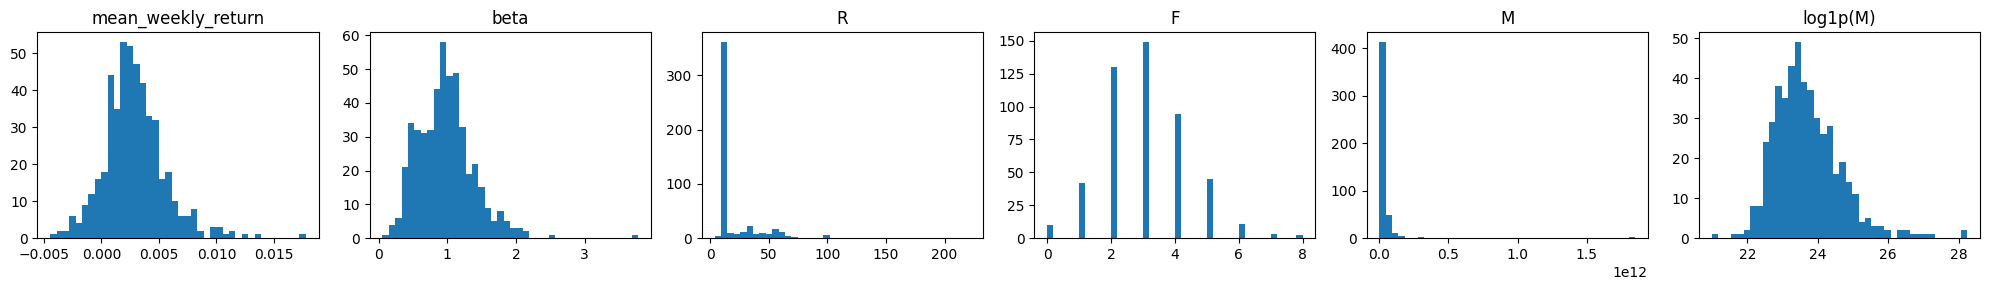


Outliers per feature (|z| > 3): {'mean_weekly_return': 6, 'beta': 2, 'R': 11, 'F': 5, 'M': 5}
Highest beta: {'CVNA': 3.78, 'XYZ': 2.5, 'COHR': 2.14}
Longest R: {'NVDA': 222, 'WEC': 151, 'COR': 102}

Matrix A: (486, 2) | Matrix B: (486, 3)


In [20]:
shares = features.index           # the same shares are used for all four solutions

# Matrix A: risk and return
A = features.loc[shares, ['mean_weekly_return', 'beta']].copy()

# Matrix B: trading activity, with log1p on M because it is very skewed
B = features.loc[shares, ['R', 'F']].copy()
B['log1p_M'] = np.log1p(features.loc[shares, 'M'])

cols = ['mean_weekly_return', 'beta', 'R', 'F', 'M']
print('Skewness:')
print(features[cols].skew().round(2))
print('log1p(M) skewness:', round(B['log1p_M'].skew(), 2))

# Histograms
fig, ax = plt.subplots(1, 6, figsize=(20, 3))
for i in range(5):
    ax[i].hist(features[cols[i]], bins=40)
    ax[i].set_title(cols[i])
ax[5].hist(B['log1p_M'], bins=40)
ax[5].set_title('log1p(M)')
plt.tight_layout()
plt.savefig(SAVE + 'fig_histograms.png', dpi=150)
plt.show()

# Outliers: more than 3 standard deviations from the mean (kept, not removed)
z = (features[cols] - features[cols].mean()) / features[cols].std()
print('\nOutliers per feature (|z| > 3):', (z.abs() > 3).sum().to_dict())
print('Highest beta:', features['beta'].nlargest(3).round(2).to_dict())
print('Longest R:', features['R'].nlargest(3).to_dict())

# Standardise each matrix on its own (mean 0, standard deviation 1)
XA = StandardScaler().fit_transform(A)
XB = StandardScaler().fit_transform(B)
print('\nMatrix A:', XA.shape, '| Matrix B:', XB.shape)

## 2.2 Agglomerative clustering (Ward)
Ward dendrograms for both matrices, and silhouette and cluster sizes for k = 2 to 8. The second cell shows profiles for other k values.

A: risk-return - last 8 merge heights: [ 5.9  8.3  8.3 11.6 12.7 14.2 18.8 23.1]
B: RFM - last 8 merge heights: [10.  10.5 11.3 13.6 15.2 15.8 23.  26.7]


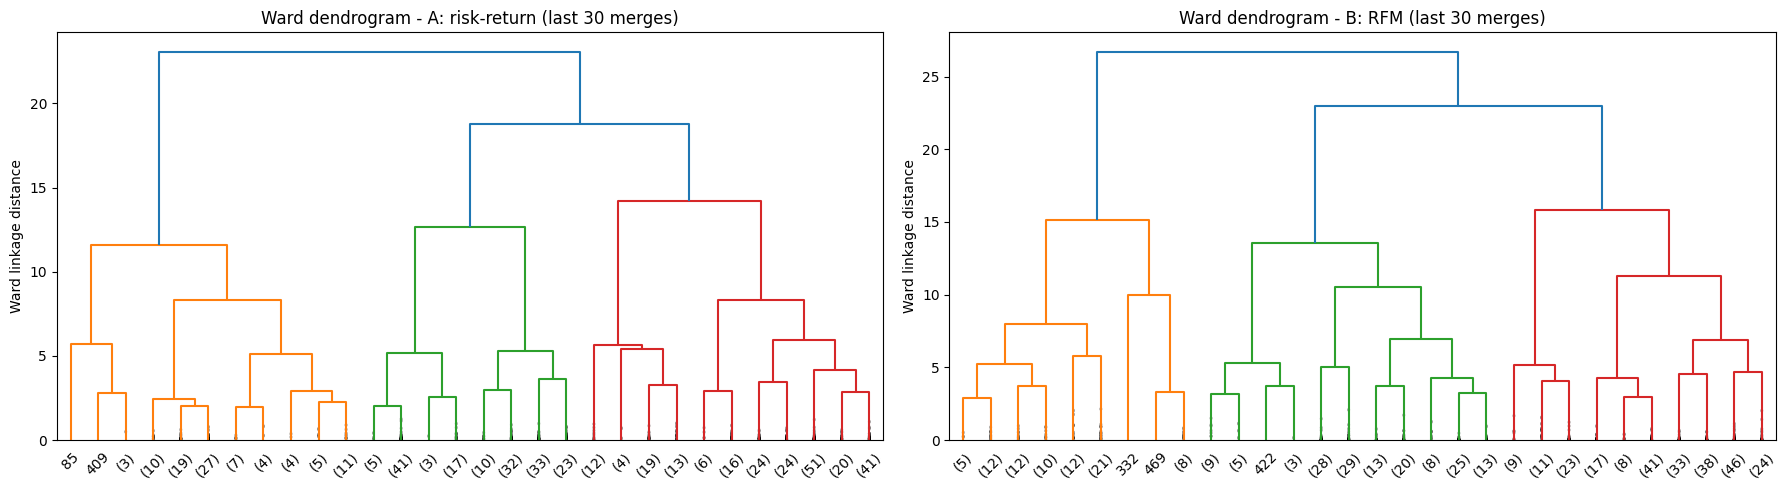

        matrix  k  silhouette                             sizes
A: risk-return  2       0.339                         [394, 92]
A: risk-return  3       0.274                    [230, 164, 92]
A: risk-return  4       0.282                [182, 164, 92, 48]
A: risk-return  5       0.304             [182, 98, 92, 66, 48]
A: risk-return  6       0.320          [182, 98, 87, 66, 48, 5]
A: risk-return  7       0.324      [160, 98, 87, 66, 48, 22, 5]
A: risk-return  8       0.321  [160, 98, 66, 56, 48, 31, 22, 5]
        B: RFM  2       0.368                         [404, 82]
        B: RFM  3       0.304                    [250, 154, 82]
        B: RFM  4       0.289                [207, 154, 82, 43]
        B: RFM  5       0.305            [207, 154, 72, 43, 10]
        B: RFM  6       0.314        [207, 136, 72, 43, 18, 10]
        B: RFM  7       0.292    [141, 136, 72, 66, 43, 18, 10]
        B: RFM  8       0.302 [141, 79, 72, 66, 57, 43, 18, 10]


In [21]:
matrices = {'A: risk-return': XA, 'B: RFM': XB}

# Dendrograms, one per matrix (only the last 30 merges are drawn so it is readable)
ward_Z = {}
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
i = 0
for name in matrices:
    Z = linkage(matrices[name], method='ward', metric='euclidean')
    ward_Z[name] = Z
    dendrogram(Z, ax=axes[i], truncate_mode='lastp', p=30, show_contracted=True)
    axes[i].set_title('Ward dendrogram - ' + name + ' (last 30 merges)')
    axes[i].set_ylabel('Ward linkage distance')
    print(name, '- last 8 merge heights:', np.round(Z[-8:, 2], 1))
    i = i + 1
plt.tight_layout()
plt.savefig(SAVE + 'fig_dendrograms.png', dpi=150)
plt.show()

# Compare k = 2 to 8 with silhouette and cluster sizes
rows = []
for name in matrices:
    for k in range(2, 9):
        labels = fcluster(ward_Z[name], k, criterion='maxclust')
        sizes = sorted(pd.Series(labels).value_counts().tolist(), reverse=True)
        sil = silhouette_score(matrices[name], labels)
        rows.append({'matrix': name, 'k': k, 'silhouette': round(sil, 3), 'sizes': sizes})

ward_eval = pd.DataFrame(rows)
ward_eval.to_csv(SAVE + 'ward_k_comparison.csv', index=False)
print(ward_eval.to_string(index=False))

In [22]:
# Profiles for other k values, to see what each choice of k actually separates
profile_cols = {'A: risk-return': ['mean_weekly_return', 'beta'], 'B: RFM': ['R', 'F', 'M']}

for name in matrices:
    for k in [2, 3, 5, 6]:
        labels = fcluster(ward_Z[name], k, criterion='maxclust')
        groups = features.loc[shares, profile_cols[name]].groupby(labels)
        prof = groups.mean()
        if name == 'B: RFM':
            prof['M'] = groups['M'].median() / 1e9       # median traded value, $bn
        prof['n'] = groups.size()
        print('\n' + name + ', Ward k=' + str(k))
        print(prof.round(4))


A: risk-return, Ward k=2
   mean_weekly_return    beta    n
1              0.0063  1.2981   92
2              0.0020  0.8979  394

A: risk-return, Ward k=3
   mean_weekly_return    beta    n
1              0.0063  1.2981   92
2              0.0029  0.6012  164
3              0.0015  1.1096  230

A: risk-return, Ward k=5
   mean_weekly_return    beta    n
1              0.0063  1.2981   92
2              0.0009  0.4390   66
3              0.0042  0.7104   98
4              0.0020  1.6280   48
5              0.0013  0.9728  182

A: risk-return, Ward k=6
   mean_weekly_return    beta    n
1              0.0129  2.3386    5
2              0.0059  1.2383   87
3              0.0009  0.4390   66
4              0.0042  0.7104   98
5              0.0020  1.6280   48
6              0.0013  0.9728  182

B: RFM, Ward k=2
         R       F        M    n
1  58.3049  2.0976  17.8490   82
2  12.7153  3.1708  16.0473  404

B: RFM, Ward k=3
         R       F        M    n
1  58.3049  2.0976  17.8490 

## 2.3 K-means clustering
K-means with a fixed seed and 20 starts, comparing silhouette, inertia and cluster sizes for k = 2 to 8.

        matrix  k  silhouette  inertia                             sizes
A: risk-return  2       0.387    621.6                        [343, 143]
A: risk-return  3       0.329    461.2                   [202, 165, 119]
A: risk-return  4       0.327    371.6               [160, 154, 132, 40]
A: risk-return  5       0.341    309.6           [166, 131, 112, 50, 27]
A: risk-return  6       0.334    265.4        [158, 113, 111, 56, 43, 5]
A: risk-return  7       0.331    227.5      [143, 85, 83, 74, 48, 48, 5]
A: risk-return  8       0.354    194.4  [136, 79, 78, 76, 43, 40, 29, 5]
        B: RFM  2       0.423   1066.8                         [418, 68]
        B: RFM  3       0.325    796.6                    [270, 152, 64]
        B: RFM  4       0.341    609.8                [212, 122, 91, 61]
        B: RFM  5       0.358    514.7            [198, 122, 87, 68, 11]
        B: RFM  6       0.346    437.4       [141, 120, 104, 69, 41, 11]
        B: RFM  7       0.347    386.3    [141, 120

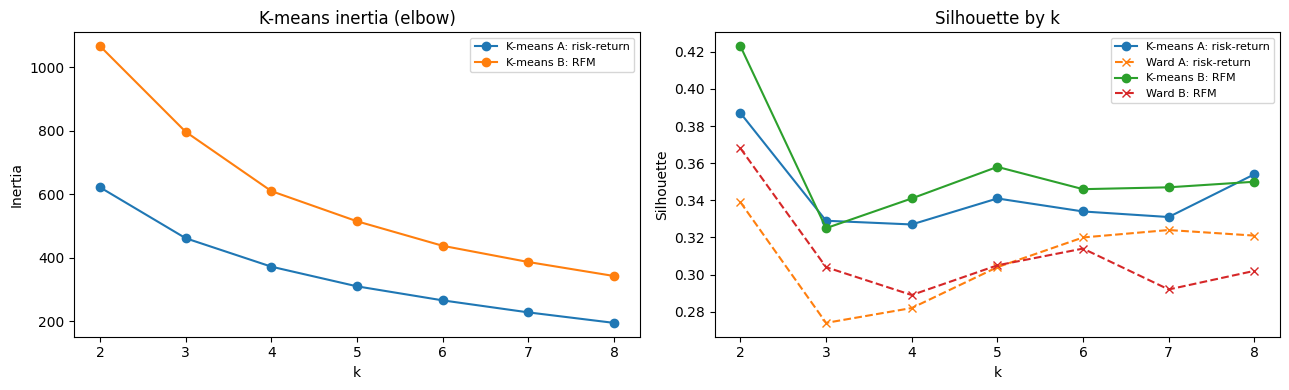

In [23]:
# random_state fixes the seed; n_init=20 runs k-means++ 20 times and keeps the best
rows = []
for name in matrices:
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(matrices[name])
        sizes = sorted(pd.Series(km.labels_).value_counts().tolist(), reverse=True)
        sil = silhouette_score(matrices[name], km.labels_)
        rows.append({'matrix': name, 'k': k, 'silhouette': round(sil, 3),
                     'inertia': round(km.inertia_, 1), 'sizes': sizes})

km_eval = pd.DataFrame(rows)
km_eval.to_csv(SAVE + 'kmeans_k_comparison.csv', index=False)
print(km_eval.to_string(index=False))

# Elbow plot (inertia) and silhouette for both methods
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in matrices:
    km_rows = km_eval[km_eval['matrix'] == name]
    ward_rows = ward_eval[ward_eval['matrix'] == name]
    axes[0].plot(km_rows['k'], km_rows['inertia'], marker='o', label='K-means ' + name)
    axes[1].plot(km_rows['k'], km_rows['silhouette'], marker='o', label='K-means ' + name)
    axes[1].plot(ward_rows['k'], ward_rows['silhouette'], marker='x', linestyle='--',
                 label='Ward ' + name)
axes[0].set_title('K-means inertia (elbow)')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[1].set_title('Silhouette by k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette')
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(SAVE + 'fig_k_selection.png', dpi=150)
plt.show()

## 2.4 Cluster profiles and algorithm comparison
Final k = 5 solutions, cluster profiles in original units, Ward vs K-means agreement (ARI) and the cluster plots.


A_ward
        mean_weekly_return    beta    n
A_ward                                 
1                   0.0063  1.2981   92
2                   0.0009  0.4390   66
3                   0.0042  0.7104   98
4                   0.0020  1.6280   48
5                   0.0013  0.9728  182

A_kmeans
          mean_weekly_return    beta    n
A_kmeans                                 
1                     0.0003  1.0200  112
2                     0.0043  0.9964  166
3                     0.0021  0.5335  131
4                     0.0093  1.5595   27
5                     0.0024  1.6315   50

B_ward
               R       F  M_mean_$bn  M_median_$bn    n
B_ward                                                 
1        50.1806  2.3889     25.9669       17.6823   72
2       116.8000  0.0000    199.7420       23.7859   10
3        13.6818  2.8636     80.1452       39.6955  154
4        16.8372  5.3721     14.9622       14.4300   43
5        11.1401  2.9420     11.0998       10.7853  207

B_kmean

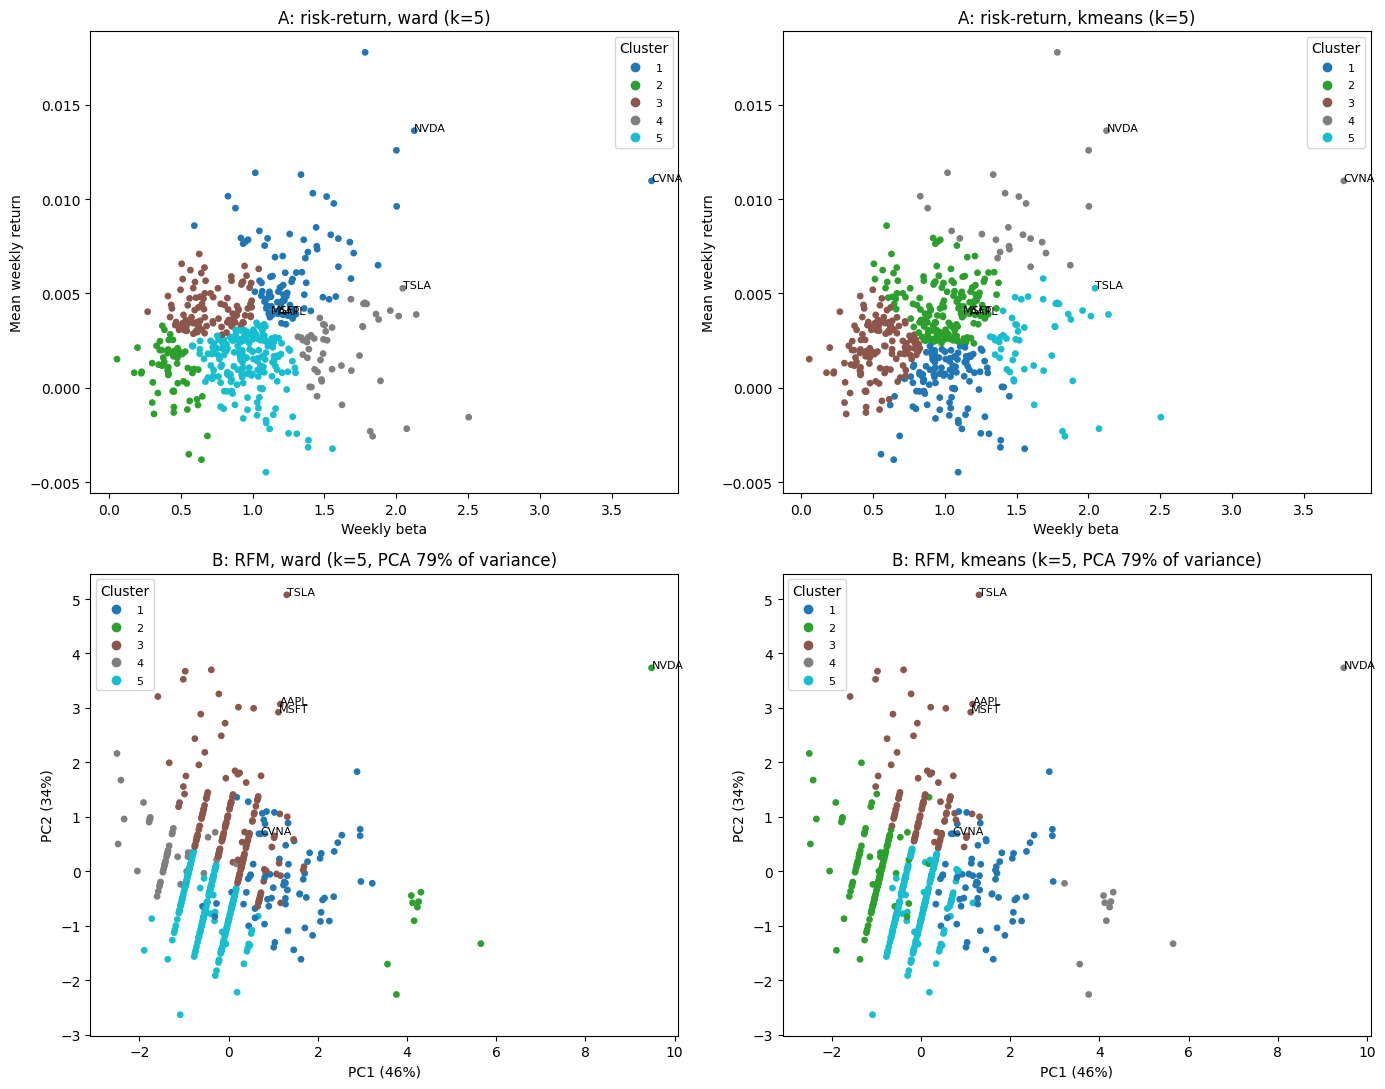

In [24]:
K = 5     # chosen number of clusters for both matrices and both algorithms

# The four final solutions (labels start at 1)
assign = pd.DataFrame(index=shares)
assign['A_ward'] = fcluster(ward_Z['A: risk-return'], K, criterion='maxclust')
assign['A_kmeans'] = KMeans(n_clusters=K, n_init=20, random_state=42).fit(XA).labels_ + 1
assign['B_ward'] = fcluster(ward_Z['B: RFM'], K, criterion='maxclust')
assign['B_kmeans'] = KMeans(n_clusters=K, n_init=20, random_state=42).fit(XB).labels_ + 1
assign = assign.join(features[['Security', 'GICS Sector']])
assign.to_csv(SAVE + 'cluster_assignments.csv')

# Profiles in original units
for col in ['A_ward', 'A_kmeans']:
    groups = features.loc[shares, ['mean_weekly_return', 'beta']].groupby(assign[col])
    prof = groups.mean()
    prof['n'] = groups.size()
    prof.to_csv(SAVE + 'profile_' + col + '.csv')
    print('\n' + col)
    print(prof.round(4))

for col in ['B_ward', 'B_kmeans']:
    groups = features.loc[shares, ['R', 'F', 'M']].groupby(assign[col])
    prof = pd.DataFrame({'R': groups['R'].mean(),
                         'F': groups['F'].mean(),
                         'M_mean_$bn': groups['M'].mean() / 1e9,
                         'M_median_$bn': groups['M'].median() / 1e9,
                         'n': groups.size()})
    prof.to_csv(SAVE + 'profile_' + col + '.csv')
    print('\n' + col)
    print(prof.round(4))

# Ward vs K-means on the same shares
for m in ['A', 'B']:
    ari = adjusted_rand_score(assign[m + '_ward'], assign[m + '_kmeans'])
    print('\n' + m + ': ARI Ward vs K-means =', round(ari, 3))
    print(pd.crosstab(assign[m + '_ward'], assign[m + '_kmeans'],
                      rownames=['Ward'], colnames=['K-means']))

# PCA to draw Matrix B (3 features) in 2D
pca = PCA(n_components=2).fit(XB)
PB = pca.transform(XB)
ev = pca.explained_variance_ratio_
print('\nRFM PCA explained variance:', ev.round(3), '| total', round(ev.sum(), 3))
loadings = pd.DataFrame(pca.components_.T, index=['R', 'F', 'log1p_M'], columns=['PC1', 'PC2'])
print(loadings.round(2))

# 2 x 2 plot: top row Matrix A in original units, bottom row Matrix B on the PCA axes
label_these = ['NVDA', 'TSLA', 'AAPL', 'MSFT', 'CVNA']
share_list = list(shares)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for j, alg in enumerate(['ward', 'kmeans']):
    ax = axes[0, j]
    sc = ax.scatter(features.loc[shares, 'beta'], features.loc[shares, 'mean_weekly_return'],
                    c=assign['A_' + alg], cmap='tab10', s=15)
    ax.set_title('A: risk-return, ' + alg + ' (k=5)')
    ax.set_xlabel('Weekly beta')
    ax.set_ylabel('Mean weekly return')
    ax.legend(*sc.legend_elements(), title='Cluster', fontsize=8)
    for s in label_these:
        ax.annotate(s, (features.loc[s, 'beta'], features.loc[s, 'mean_weekly_return']), fontsize=8)

    ax = axes[1, j]
    sc = ax.scatter(PB[:, 0], PB[:, 1], c=assign['B_' + alg], cmap='tab10', s=15)
    ax.set_title('B: RFM, ' + alg + ' (k=5, PCA ' + str(round(ev.sum() * 100)) + '% of variance)')
    ax.set_xlabel('PC1 (' + str(round(ev[0] * 100)) + '%)')
    ax.set_ylabel('PC2 (' + str(round(ev[1] * 100)) + '%)')
    ax.legend(*sc.legend_elements(), title='Cluster', fontsize=8)
    for s in label_these:
        row = share_list.index(s)          # position of the share in PB
        ax.annotate(s, (PB[row, 0], PB[row, 1]), fontsize=8)
plt.tight_layout()
plt.savefig(SAVE + 'fig_cluster_plots.png', dpi=150)
plt.show()

## 2.5 RFM sensitivity and correlated inputs
Correlations between R, F and log1p(M), then Ward repeated without M to see what M adds.

In [25]:
# Correlations between R, F and log1p(M)
corr = B[['R', 'F', 'log1p_M']].corr().round(2)
corr.to_csv(SAVE + 'rfm_correlations.csv')
print('Pearson correlations:')
print(corr)

# Remove Monetary: Ward on R and F only, same shares, same k, standardised again
XB_rf = StandardScaler().fit_transform(features.loc[shares, ['R', 'F']])
assign['B_ward_RF_only'] = fcluster(linkage(XB_rf, method='ward'), K, criterion='maxclust')
assign.to_csv(SAVE + 'cluster_assignments.csv')

ari_rf = adjusted_rand_score(assign['B_ward'], assign['B_ward_RF_only'])
print('\nARI, full RFM Ward vs R+F-only Ward:', round(ari_rf, 3))
rf_table = pd.crosstab(assign['B_ward'], assign['B_ward_RF_only'],
                       rownames=['Full RFM'], colnames=['R+F only'])
rf_table.to_csv(SAVE + 'rf_only_crosstab.csv')
print(rf_table)

# Traded value in each cluster, with and without M
for col in ['B_ward', 'B_ward_RF_only']:
    groups = features.loc[shares].groupby(assign[col])
    prof = pd.DataFrame({'R': groups['R'].mean(),
                         'F': groups['F'].mean(),
                         'M_median_$bn': groups['M'].median() / 1e9,
                         'n': groups.size()})
    prof.to_csv(SAVE + 'traded_value_' + col + '.csv')
    print('\n' + col)
    print(prof.round(2))

Pearson correlations:
            R     F  log1p_M
R        1.00 -0.35     0.15
F       -0.35  1.00     0.01
log1p_M  0.15  0.01     1.00

ARI, full RFM Ward vs R+F-only Ward: 0.335
R+F only   1   2   3   4    5
Full RFM                     
1          0  69   0   1    2
2         10   0   0   0    0
3          0   9  59  17   69
4          0   1   0  41    1
5          0   0  66   2  139

B_ward
             R     F  M_median_$bn    n
B_ward                                 
1        50.18  2.39         17.68   72
2       116.80  0.00         23.79   10
3        13.68  2.86         39.70  154
4        16.84  5.37         14.43   43
5        11.14  2.94         10.79  207

B_ward_RF_only
                     R     F  M_median_$bn    n
B_ward_RF_only                                 
1               116.80  0.00         23.79   10
2                48.94  2.27         20.13   79
3                11.04  1.80         17.70  125
4                16.44  5.38         16.89   61
5               

## 3.2 Supporting evidence: sector composition
Sector mix of each cluster, and the agreement between risk-return and RFM clusters.

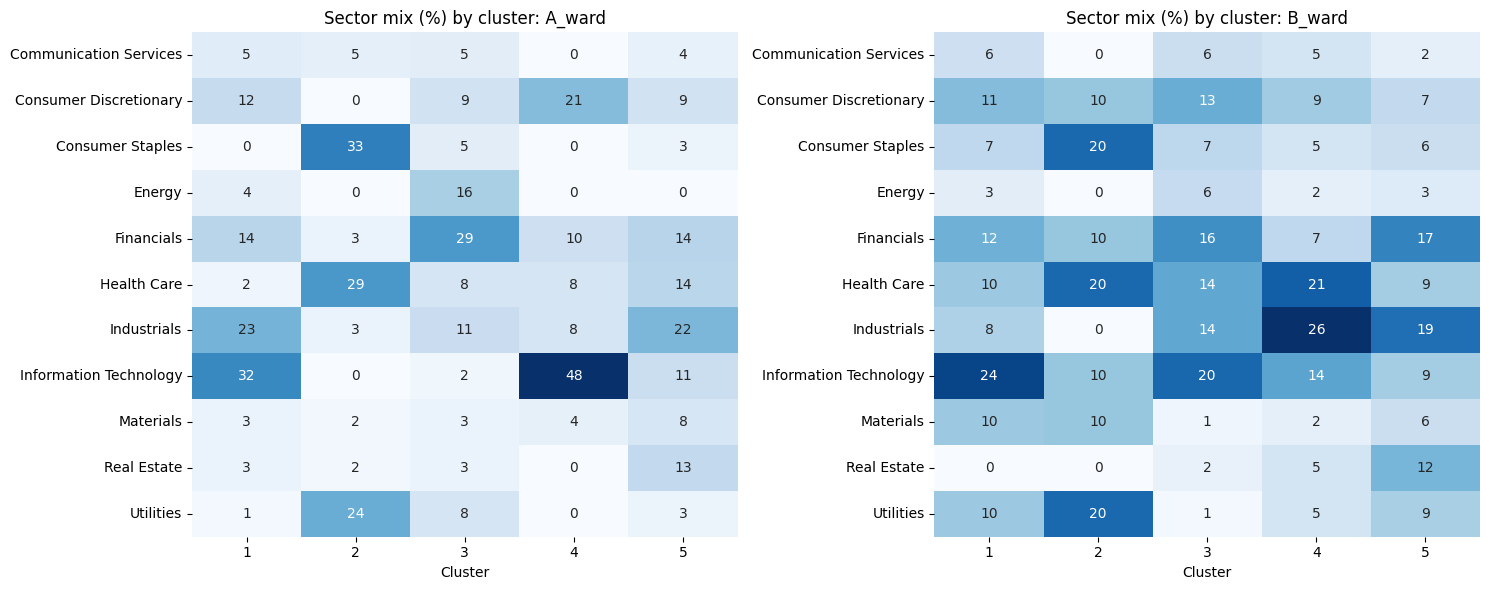

ARI, risk-return clusters vs RFM clusters (Ward): 0.043
RFM           1  2   3   4    5
Risk-return                    
1            18  1  37  12   24
2            11  5  23   4   23
3             7  3  35   6   47
4             8  1  20   6   13
5            28  0  39  15  100


In [26]:
sector = assign['GICS Sector']

# Percentage of each sector inside each cluster
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for i, col in enumerate(['A_ward', 'B_ward']):
    mix = pd.crosstab(sector, assign[col], normalize='columns') * 100
    mix.round(0).to_csv(SAVE + 'sector_mix_' + col + '.csv')
    sns.heatmap(mix, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=axes[i])
    axes[i].set_title('Sector mix (%) by cluster: ' + col)
    axes[i].set_xlabel('Cluster')
    axes[i].set_ylabel('')
plt.tight_layout()
plt.savefig(SAVE + 'fig_sector_mix.png', dpi=150)
plt.show()

# Do the risk-return groups and the activity groups overlap?
ari_ab = adjusted_rand_score(assign['A_ward'], assign['B_ward'])
print('ARI, risk-return clusters vs RFM clusters (Ward):', round(ari_ab, 3))
print(pd.crosstab(assign['A_ward'], assign['B_ward'], rownames=['Risk-return'], colnames=['RFM']))